# HYDAT daily mean streamflow and gauge level

Inspect historical observations from Water Survey of Canada gauge `02HA014` (Redhill Creek at Hamilton) for 2020, via ECCC GeoMet. Daily mean discharge is reported in m³/s and daily mean gauge level in metres. A gauge's vertical datum is station-specific and is **not established by this daily response**. Gauge level is not flood depth at an asset or necessarily elevation above sea level. Daily means are not instantaneous peak flows.

The [companion pipeline](../../pipelines/hydat_daily_pipeline.py) captures source features in bounded pages and records per-page and snapshot checksums. It preserves nulls and the source's English and French symbols without applying a quality policy. An `Ice Conditions` symbol means ice may affect discharge estimates; see the [Water Survey FAQ](https://wateroffice.ec.gc.ca/contactus/faq_e.html) and [datum guidance](https://wateroffice.ec.gc.ca/report/datum_faq_e.html).

Data source: Environment and Climate Change Canada, [Historical Hydrometric Data](https://open.canada.ca/data/en/dataset/1ee9e14d-0814-5201-a3be-705809d8ee0e), Open Government Licence – Canada; see also the [ECCC data services licence](https://eccc-msc.github.io/open-data/licence/readme_en/).

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.hydat_daily_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "hydat_daily"
summary = run(output)
print("Observations:", summary["observations"])
for source in summary["sources"]:
    print(source["year"], "snapshot:", source["sha256"], "retrieved:", source["retrieved_at"])

Observations: 366
2020 snapshot: e6a4a5b5810d9dd6208a1eef97083f673b384afc0531b1653272a1d3dda87bbf retrieved: 2026-10-30T19:26:20.442347+00:00


In [2]:
# This single-year example is small; the pipeline streams Arrow batches to Parquet.
daily = pq.read_table(output / "daily.parquet").to_pandas()
print("Unique dates:", daily["date"].nunique(), "of 366")
print("Null discharge values:", daily["discharge_m3_s"].isna().sum())
print("Discharge symbols:", daily["discharge_symbol_en"].value_counts(dropna=False).to_dict())
daily.sort_values("date")[["date", "discharge_m3_s", "discharge_symbol_en", "level_m", "level_symbol_en"]].head()

Unique dates: 366 of 366
Null discharge values: 0
Discharge symbols: {nan: 323, 'Estimated': 38, 'Ice Conditions': 5}


,date,discharge_m3_s,discharge_symbol_en,level_m,level_symbol_en
0,2020-01-01,0.921,NaN,11.426,NaN
1,2020-01-02,0.678,NaN,11.397,NaN
2,2020-01-03,0.580,NaN,11.383,NaN
3,2020-01-04,0.804,NaN,11.411,NaN
4,2020-01-05,0.585,NaN,11.383,NaN


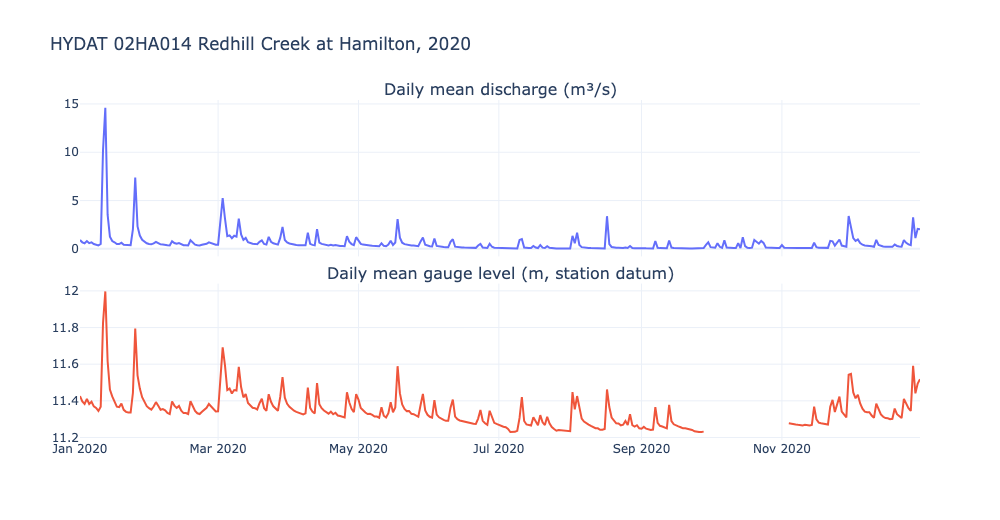

In [3]:
# Daily mean discharge and gauge level; missing values stay gaps.
view = daily.sort_values("date")
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=("Daily mean discharge (m³/s)", "Daily mean gauge level (m, station datum)"))
fig.add_trace(go.Scatter(x=view["date"], y=view["discharge_m3_s"], mode="lines", connectgaps=False), row=1, col=1)
fig.add_trace(go.Scatter(x=view["date"], y=view["level_m"], mode="lines", connectgaps=False), row=2, col=1)
fig.update_layout(title="HYDAT 02HA014 Redhill Creek at Hamilton, 2020", showlegend=False, height=520)
fig.show()


Review the station's record, datum, changes in monitoring and quality symbols before comparing series or fitting extremes. GeoMet may revise historical data, and sequential pages are not a transactional upstream snapshot; retain the cache and manifest for replay. These observations do not by themselves describe inundation or losses.